In [3]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge,Lasso,ElasticNet
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score


In [4]:
df = pd.read_csv("Housing.csv")
df.head()


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [6]:
X = df.drop("price",axis=1)
y = df["price"]


In [7]:
X = pd.get_dummies(X,drop_first=True)

In [8]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled =  scaler.transform(X_test)

In [10]:
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled,y_train)
ridge_pred = ridge.predict(X_test_scaled)

In [11]:
ridge_mse = mean_squared_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(ridge_mse)
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_r2 = r2_score(y_test, ridge_pred)

print("Ridge MSE:", ridge_mse)
print("Ridge RMSE:", ridge_rmse)
print("Ridge MAE:", ridge_mae)
print("Ridge R2:", ridge_r2)

Ridge MSE: 1754839327446.8074
Ridge RMSE: 1324703.4866138187
Ridge MAE: 969857.9028478259
Ridge R2: 0.6528212603810125


In [12]:
lasso = Lasso(alpha=0.1,max_iter=10000)
lasso.fit(X_train_scaled,y_train)
lasso_pred = lasso.predict(X_test_scaled)

In [13]:
lasso_mse = mean_squared_error(y_test, lasso_pred)
lasso_rmse = np.sqrt(lasso_mse)
lasso_mae = mean_absolute_error(y_test, lasso_pred)
lasso_r2 = r2_score(y_test, lasso_pred)

print("Lasso MSE:", lasso_mse)
print("Lasso RMSE:", lasso_rmse)
print("Lasso MAE:", lasso_mae)
print("Lasso R2:", lasso_r2)

Lasso MSE: 1754318818534.6665
Lasso RMSE: 1324507.0096208123
Lasso MAE: 970043.4045634499
Lasso R2: 0.6529242382578193


In [14]:
elastic = ElasticNet(
    alpha=0.1,
    l1_ratio=0.5,
    max_iter=10000
)

elastic.fit(X_train_scaled, y_train)

elastic_pred = elastic.predict(X_test_scaled)

In [15]:
elastic_mse = mean_squared_error(y_test, elastic_pred)
elastic_rmse = np.sqrt(elastic_mse)
elastic_mae = mean_absolute_error(y_test, elastic_pred)
elastic_r2 = r2_score(y_test, elastic_pred)

print("ElasticNet MSE:", elastic_mse)
print("ElasticNet RMSE:", elastic_rmse)
print("ElasticNet MAE:", elastic_mae)
print("ElasticNet R2:", elastic_r2)

ElasticNet MSE: 1768275139548.0215
ElasticNet RMSE: 1329765.0693066132
ElasticNet MAE: 966929.9333160252
ElasticNet R2: 0.650163109154231


In [16]:
results = pd.DataFrame({
    "Model": ["Ridge", "Lasso", "ElasticNet"],
    "MAE": [ridge_mae, lasso_mae, elastic_mae],
    "MSE": [ridge_mse, lasso_mse, elastic_mse],
    "RMSE": [ridge_rmse, lasso_rmse, elastic_rmse],
    "R2": [ridge_r2, lasso_r2, elastic_r2]
})

results

,Model,MAE,MSE,RMSE,R2
0,Ridge,969857.902848,1.754839e+12,1.324703e+06,0.652821
1,Lasso,970043.404563,1.754319e+12,1.324507e+06,0.652924
2,ElasticNet,966929.933316,1.768275e+12,1.329765e+06,0.650163


In [17]:
alphas = [0.01,0.1,1,10,100]

In [18]:
ridge_coefs = []

for alpha in alphas:
    model = Ridge(alpha=alpha)
    model.fit(X_train_scaled, y_train)
    ridge_coefs.append(model.coef_)

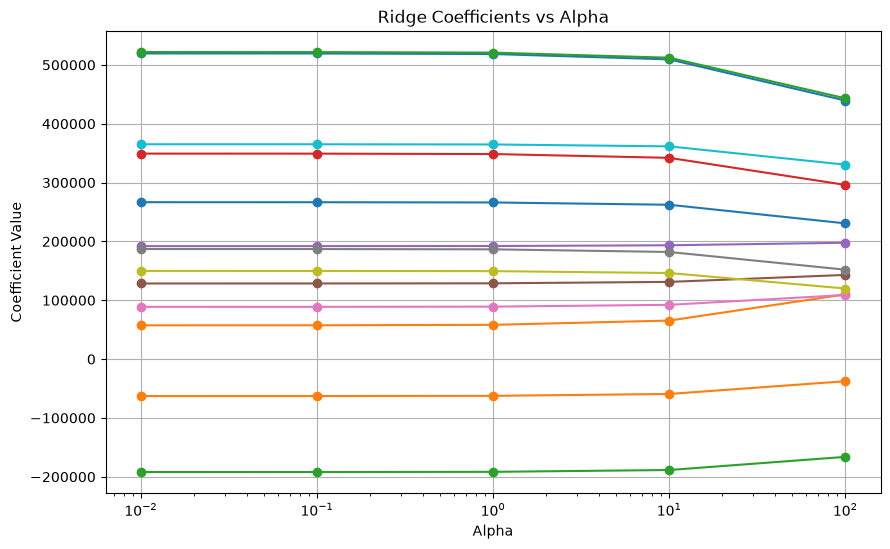

In [19]:
ridge_coefs = np.array(ridge_coefs)

plt.figure(figsize=(10, 6))

for i in range(ridge_coefs.shape[1]):
    plt.plot(alphas, ridge_coefs[:, i], marker='o')

plt.xscale("log")
plt.xlabel("Alpha")
plt.ylabel("Coefficient Value")
plt.title("Ridge Coefficients vs Alpha")
plt.grid(True)
plt.show()

In [20]:
lasso_coefs = []

for alpha in alphas:
    model = Lasso(alpha=alpha,max_iter=10000)
    model.fit(X_train_scaled, y_train)
    lasso_coefs.append(model.coef_)

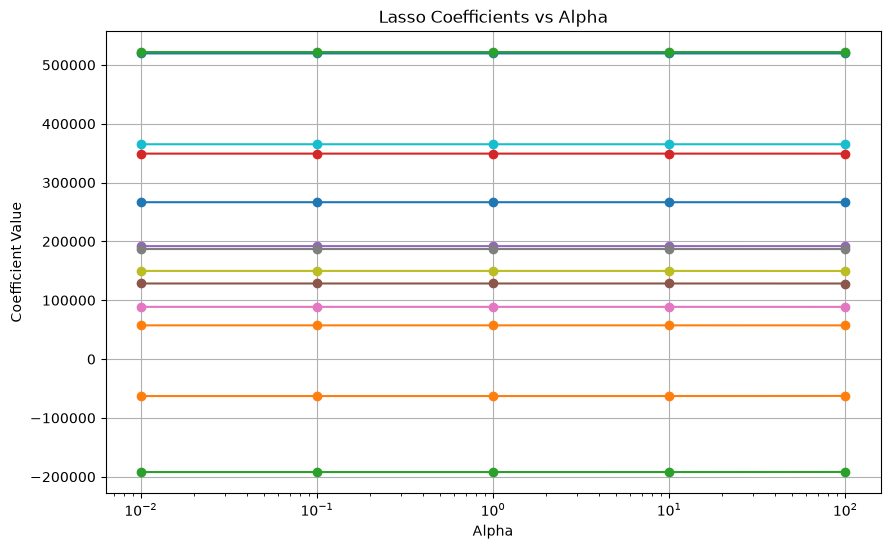

In [21]:
lasso_coefs = np.array(lasso_coefs)

plt.figure(figsize=(10, 6))

for i in range(lasso_coefs.shape[1]):
    plt.plot(alphas, lasso_coefs[:, i], marker='o')

plt.xscale("log")
plt.xlabel("Alpha")
plt.ylabel("Coefficient Value")
plt.title("Lasso Coefficients vs Alpha")
plt.grid(True)
plt.show()

In [22]:
elastic_coefs = []

for alpha in alphas:
    model = ElasticNet(
        alpha=alpha,
        l1_ratio=0.5,
        max_iter=10000
    )

    model.fit(X_train_scaled, y_train)
    elastic_coefs.append(model.coef_)

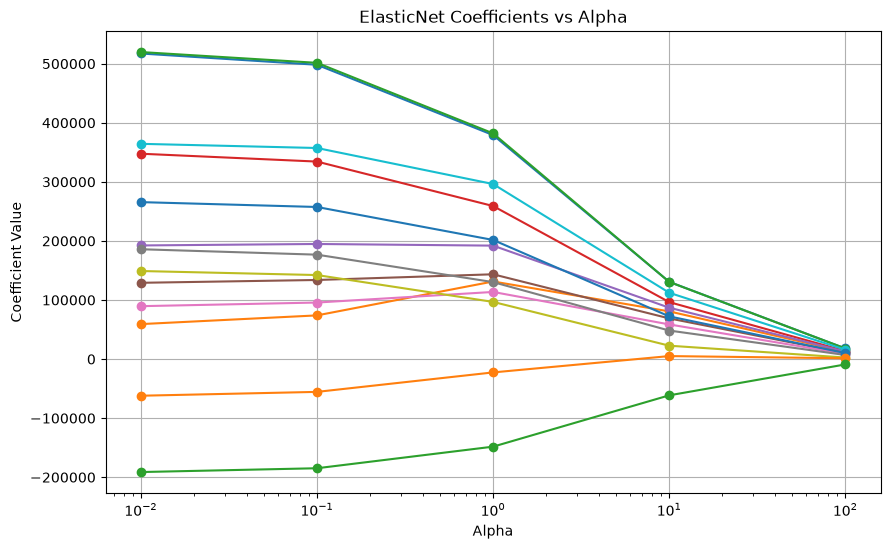

In [23]:
elastic_coefs = np.array(elastic_coefs)

plt.figure(figsize=(10, 6))

for i in range(elastic_coefs.shape[1]):
    plt.plot(alphas, elastic_coefs[:, i], marker='o')

plt.xscale("log")
plt.xlabel("Alpha")
plt.ylabel("Coefficient Value")
plt.title("ElasticNet Coefficients vs Alpha")
plt.grid(True)
plt.show()

In [24]:
ridge_errors = []

for alpha in alphas:
    model = Ridge(alpha=alpha)
    model.fit(X_train_scaled, y_train)

    pred = model.predict(X_test_scaled)

    mse = mean_squared_error(y_test, pred)
    ridge_errors.append(mse)

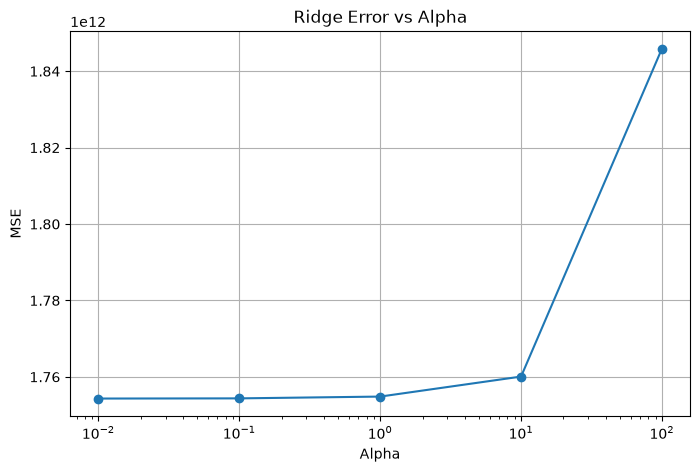

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(alphas, ridge_errors, marker='o')

plt.xscale("log")
plt.xlabel("Alpha")
plt.ylabel("MSE")
plt.title("Ridge Error vs Alpha")
plt.grid(True)
plt.show()